
# CA1 - Comprehensive Model Comparison


### Models included:
- Logistic Regression
- K-Nearest Neighbors (KNN)
- Naive Bayes
- Random Forest
- Gradient Boosting

### Steps:
1. Load and split data (train, validation, test)
2. Train and evaluate each model
3. Compare validation and test accuracies
4. Visualize confusion matrices and ROC curves
5. Save the best-performing model using `joblib`


## 1. Import Libraries

### Explanation
This cell imports all the required Python libraries for data handling, modeling, and evaluation. We use NumPy for array operations, Matplotlib for plotting, and scikit-learn for machine learning models and metrics.

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc
import joblib


## 2. Load and Prepare Dataset

### Explanation
Here we load the cleaned dataset using NumPy’s `genfromtxt`. we remove rows that are equal to zero in the dataset to help make the models more accurate

In [3]:

file = "Data1674.csv"
data = np.genfromtxt(
    file,
    delimiter=",",
    dtype=float,
    encoding='utf-8',
    invalid_raise=False,
    skip_header=1
)
unclean_row_count = data.shape[0]
data = data[~np.all(data == 0, axis=1)]
cleaned_row_count = unclean_row_count - data.shape[0]


X = data[:, :-1]
y = data[:, -1].astype(float)
feature_columns= X.shape[1]

print("Data shape:", data.shape)
print("Feature shape:", X.shape, "Target shape:", y.shape)
print("number of rows before cleaning",unclean_row_count)
print("number of rows cleaned",cleaned_row_count)
print("number of feature colums is",feature_columns)



Data shape: (4674, 15)
Feature shape: (4674, 14) Target shape: (4674,)
number of rows before cleaning 4757
number of rows cleaned 83
number of feature colums is 14


## 3. Split into Train, Validation, and Test Sets
### Explanation
We split the dataset into three parts:
- **Training set**: for fitting the models
- **Validation set**: for tuning and comparison
- **Test set**: for final unbiased evaluation

We use `stratify=y` to maintain class balance.

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("Train set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)


### Explanation
We split the dataset into three parts:
- **Training set**: for fitting the models
- **Validation set**: for tuning and comparison
- **Test set**: for final unbiased evaluation

We use `stratify=y` to maintain class balance.

In [4]:

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("Train set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)


Train set: (2804, 14)
Validation set: (935, 14)
Test set: (935, 14)


In [5]:

def plot_confusion_matrix(cm, title):
    fig, ax = plt.subplots(figsize=(3.5,3.5))
    ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center', color='black')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    plt.show()


## 4. Logistic Regression


#### Logistic Regression — Algorithm Summary
- A **linear model** for binary classification that estimates probabilities using the **logistic (sigmoid)** function.
- Finds the best-fitting line (or hyperplane) separating the two classes.
- Outputs probabilities and a decision boundary; good for **interpretable** models when classes are **linearly separable**.


Validation Accuracy: 0.6695187165775401 
Test Accuracy: 0.6705882352941176


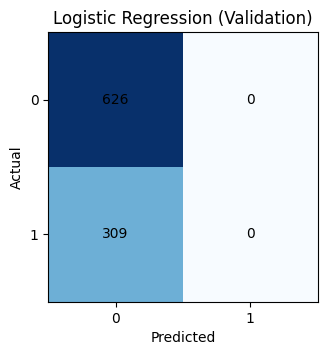

In [6]:

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)
y_val_lr = log_reg.predict(X_val)
y_test_lr = log_reg.predict(X_test)
val_acc_lr = accuracy_score(y_val, y_val_lr)
test_acc_lr = accuracy_score(y_test, y_test_lr)
cm_lr = confusion_matrix(y_val, y_val_lr)
print("Validation Accuracy:", val_acc_lr, "\nTest Accuracy:", test_acc_lr)
plot_confusion_matrix(cm_lr, "Logistic Regression (Validation)")


## 5. K-Nearest Neighbors


#### K-Nearest Neighbors (KNN) — Algorithm Summary
- A **non-parametric** method that makes predictions by looking at the **k closest samples** in the training data.
- Classification is done by **majority vote** among these neighbors.
- Works well with small datasets and **clear cluster structures**, but can be slower on large data.


Validation Accuracy: 0.6171122994652406 
Test Accuracy: 0.6053475935828877


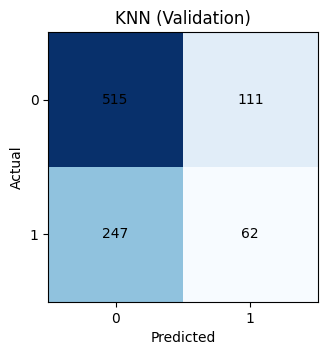

In [7]:

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_val_knn = knn.predict(X_val)
y_test_knn = knn.predict(X_test)
val_acc_knn = accuracy_score(y_val, y_val_knn)
test_acc_knn = accuracy_score(y_test, y_test_knn)
cm_knn = confusion_matrix(y_val, y_val_knn)
print("Validation Accuracy:", val_acc_knn, "\nTest Accuracy:", test_acc_knn)
plot_confusion_matrix(cm_knn, "KNN (Validation)")


## 6. Naive Bayes


#### Naive Bayes — Algorithm Summary
- A **probabilistic model** based on **Bayes’ theorem** with the assumption of **independent features**.
- Calculates the probability of each class given the input features.
- Very fast and works well even with small amounts of data, often used as a **baseline classifier**.


Validation Accuracy: 0.6695187165775401 
Test Accuracy: 0.6705882352941176


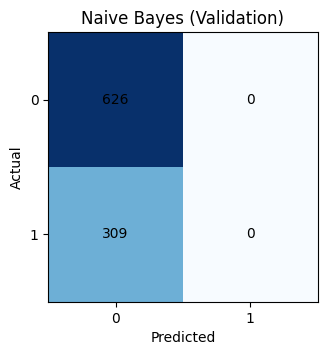

In [8]:

nb = GaussianNB()
nb.fit(X_train, y_train)
y_val_nb = nb.predict(X_val)
y_test_nb = nb.predict(X_test)
val_acc_nb = accuracy_score(y_val, y_val_nb)
test_acc_nb = accuracy_score(y_test, y_test_nb)
cm_nb = confusion_matrix(y_val, y_val_nb)
print("Validation Accuracy:", val_acc_nb, "\nTest Accuracy:", test_acc_nb)
plot_confusion_matrix(cm_nb, "Naive Bayes (Validation)")


## 7. Random Forest


#### Random Forest — Algorithm Summary
- An **ensemble method** that builds many **decision trees** on random subsets of the data and features.
- Combines their outputs (via majority vote) to reduce **variance** and improve **generalization**.
- Robust and accurate; often a strong **default choice** for tabular data.


Validation Accuracy: 0.6641711229946524 
Test Accuracy: 0.6566844919786097


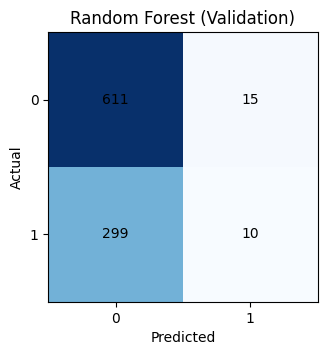

In [ ]:

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_val_rf = rf.predict(X_val)
y_test_rf = rf.predict(X_test)
val_acc_rf = accuracy_score(y_val, y_val_rf)
test_acc_rf = accuracy_score(y_test, y_test_rf)
cm_rf = confusion_matrix(y_val, y_val_rf)
print("Validation Accuracy:", val_acc_rf, "\nTest Accuracy:", test_acc_rf)
plot_confusion_matrix(cm_rf, "Random Forest (Validation)")


## 8. Gradient Boosting


#### Gradient Boosting — Algorithm Summary
- An **ensemble technique** that builds trees **sequentially**, each one learning to correct the mistakes of the previous.
- Optimizes a **loss function** by gradient descent.
- Powerful and flexible; can achieve high accuracy but may require tuning to prevent **overfitting**.


Validation Accuracy: 0.6556149732620321 
Test Accuracy: 0.6620320855614973


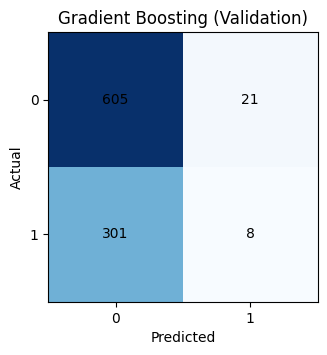

In [10]:

gbt = GradientBoostingClassifier(random_state=42)
gbt.fit(X_train, y_train)
y_val_gbt = gbt.predict(X_val)
y_test_gbt = gbt.predict(X_test)
val_acc_gbt = accuracy_score(y_val, y_val_gbt)
test_acc_gbt = accuracy_score(y_test, y_test_gbt)
cm_gbt = confusion_matrix(y_val, y_val_gbt)
print("Validation Accuracy:", val_acc_gbt, "\nTest Accuracy:", test_acc_gbt)
plot_confusion_matrix(cm_gbt, "Gradient Boosting (Validation)")


## 9. Accuracy Comparison

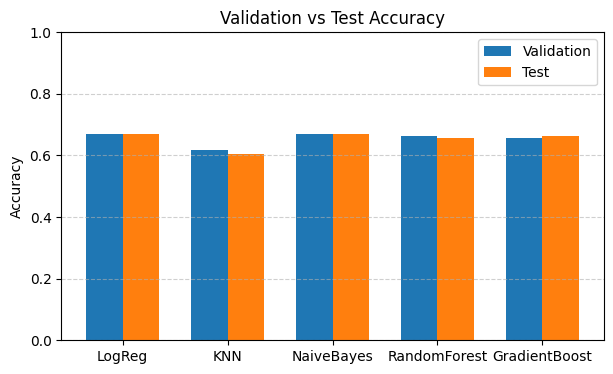

In [11]:

models = ["LogReg", "KNN", "NaiveBayes", "RandomForest", "GradientBoost"]
val_accs = [val_acc_lr, val_acc_knn, val_acc_nb, val_acc_rf, val_acc_gbt]
test_accs = [test_acc_lr, test_acc_knn, test_acc_nb, test_acc_rf, test_acc_gbt]

x = np.arange(len(models))
width = 0.35
plt.figure(figsize=(7,4))
plt.bar(x - width/2, val_accs, width, label="Validation")
plt.bar(x + width/2, test_accs, width, label="Test")
plt.xticks(x, models)
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Validation vs Test Accuracy")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


## 10. ROC Curves

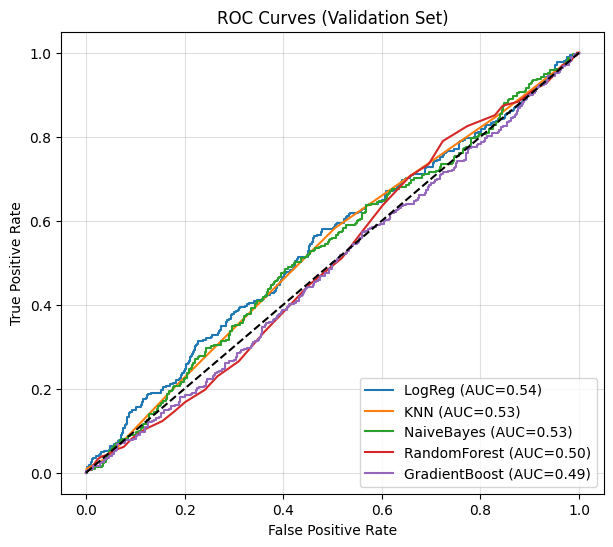

In [12]:

plt.figure(figsize=(7,6))
for name, model in [("LogReg", log_reg), ("KNN", knn), ("NaiveBayes", nb), ("RandomForest", rf), ("GradientBoost", gbt)]:
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_val)[:, 1]
        fpr, tpr, _ = roc_curve(y_val, y_prob)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (Validation Set)")
plt.legend(loc="lower right")
plt.grid(alpha=0.4)
plt.show()


## 11. Save Best Model

### Explanation
We collect all validation accuracies, identify the best-performing model, and save it to disk using `joblib` for later use.

In [13]:

val_scores = {
    "Logistic Regression": val_acc_lr,
    "K-Nearest Neighbors": val_acc_knn,
    "Naive Bayes": val_acc_nb,
    "Random Forest": val_acc_rf,
    "Gradient Boosting": val_acc_gbt
}
best_model_name = max(val_scores, key=val_scores.get)
print("Best model based on validation accuracy:", best_model_name)

best_model = {
    "Logistic Regression": log_reg,
    "K-Nearest Neighbors": knn,
    "Naive Bayes": nb,
    "Random Forest": rf,
    "Gradient Boosting": gbt
}[best_model_name]

joblib.dump(best_model, "best_pima_model.joblib")
print("Saved best model to best_pima_model.joblib")


Best model based on validation accuracy: Logistic Regression
Saved best model to best_pima_model.joblib


## 12. Summary of all Models

Logistic Regression
Validation accuracy 0.6695187165775401
Test accuracy: 0.6705882352941176

K-Nearest Neighbour
Validation accuracy 0.6171122994652406
Test accuracy: 0.6053475935828877

Naive Bays
Validation accuracy 0.6695187165775401
Test accuracy: 0.6705882352941176

Random Forest
Validation accuracy 0.6641711229946524
Test accuracy: 0.6566844919786097

Gradient Boosting
Validation accuracy 0.6556149732620321
Test accuracy: 0.6620320855614973


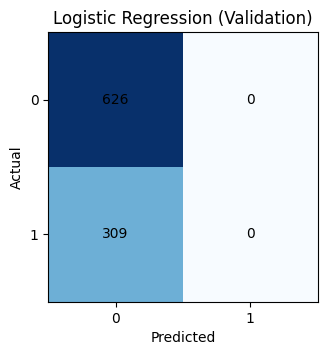

In [14]:
print("Logistic Regression")
print("Validation accuracy",val_acc_lr)
print("Test accuracy:",test_acc_lr)
print()
print("K-Nearest Neighbour")
print("Validation accuracy",val_acc_knn)
print("Test accuracy:",test_acc_knn)
print()
print("Naive Bays")
print("Validation accuracy",val_acc_nb)
print("Test accuracy:",test_acc_nb)
print()
print("Random Forest")
print("Validation accuracy",val_acc_rf)
print("Test accuracy:",test_acc_rf)
print()
print("Gradient Boosting")
print("Validation accuracy",val_acc_gbt)
print("Test accuracy:",test_acc_gbt)
plot_confusion_matrix(cm_lr, "Logistic Regression (Validation)")




## 13 Conclusion

The best model is the logistic regression because it has the highest test accuracy and validation accuracy(the naive bays model also has the same accuracy scores but logistic regression is easier to interpret)
The confusion matrix shows there is 0 False positives, 0 True positives, 626 True negatives and 309 False negatives.
This model is 66.9% accurate

Sensor Check
Enter ID: 1674
Enter number of cleaned rows (non-zero): 4674
Enter number of features: 14
Enter model code (0=LogReg, 1=KNN, 2=NaiveBayes, 3=RandomForest, 4=GradientBoosting): 0
1674 Failure

Computed from file:    
  Total rows     : 4757
  Zero rows      : 83